In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pickle
from pathlib import Path

In [3]:
data_dir = Path("cifar-10-batches-py")

def load_batch(file_path):
    with open(file_path, "rb") as f:
        batch = pickle.load(f, encoding="bytes")

    X = batch[b"data"].reshape(-1, 3, 32, 32)
    X = X.transpose(0, 2, 3, 1)
    y = np.array(batch[b"labels"])

    return X, y


X_list = []
y_list = []

for i in range(1, 6):
    X, y = load_batch(data_dir / f"data_batch_{i}")
    X_list.append(X)
    y_list.append(y)

X_train_full = np.concatenate(X_list)
y_train_full = np.concatenate(y_list)


X_test, y_test = load_batch(data_dir / "test_batch")

print("Training images:", X_train_full.shape)
print("Training labels:", y_train_full.shape)
print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)

Training images: (50000, 32, 32, 3)
Training labels: (50000,)
Test images: (10000, 32, 32, 3)
Test labels: (10000,)


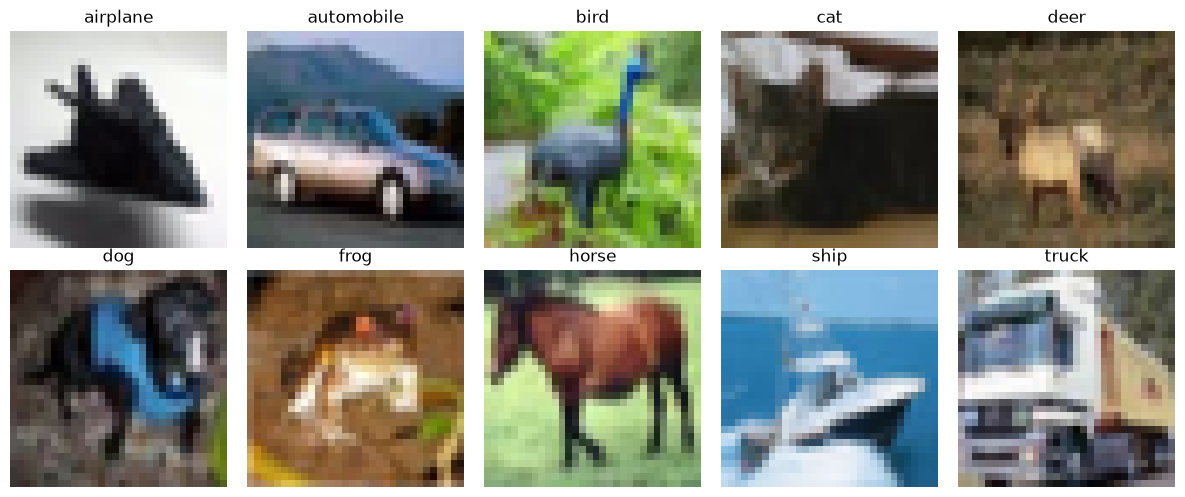

In [4]:
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    idx = np.where(y_train_full == i)[0][0]

    ax.imshow(X_train_full[idx])
    ax.set_title(class_names[i])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    train_size=5000,
    test_size=1000,
    random_state=42,
    stratify=y_train_full
)

X_test_small, _, y_test_small, _ = train_test_split(
    X_test,
    y_test,
    train_size=1000,
    random_state=42,
    stratify=y_test
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test_small.shape)

Training: (5000, 32, 32, 3)
Validation: (1000, 32, 32, 3)
Test: (1000, 32, 32, 3)


In [ ]:
X_train_flat = X_train.reshape(len(X_train), -1).astype(np.float32) / 255.0
X_val_flat = X_val.reshape(len(X_val), -1).astype(np.float32) / 255.0
X_test_flat = X_test_small.reshape(len(X_test_small), -1).astype(np.float32) / 255.0

print("Training:", X_train_flat.shape)
print("Validation:", X_val_flat.shape)
print("Test:", X_test_flat.shape)

print("Pixel range:", X_train_flat.min(), X_train_flat.max())

Training: (5000, 3072)
Validation: (1000, 3072)
Test: (1000, 3072)
Pixel range: 0.0 1.0


In [9]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

k_values = [1, 3, 5, 7, 11]
metrics = ["euclidean", "manhattan"]

results = []

for metric in metrics:
    print(f"\nDistance metric: {metric}")

    knn = KNeighborsClassifier(
        n_neighbors=max(k_values),
        metric=metric,
        algorithm="brute",
        n_jobs=-1
    )

    knn.fit(X_train_flat, y_train)

    neighbor_indices = knn.kneighbors(
        X_val_flat,
        return_distance=False
    )

    neighbor_labels = y_train[neighbor_indices]

    for k in k_values:
        predictions = np.array([
            np.bincount(labels[:k], minlength=10).argmax()
            for labels in neighbor_labels
        ])

        accuracy = accuracy_score(y_val, predictions)

        results.append({
            "k": k,
            "metric": metric,
            "accuracy": accuracy
        })

        print(f"k={k}: Accuracy={accuracy:.4f}")


Distance metric: euclidean
k=1: Accuracy=0.2580
k=3: Accuracy=0.2710
k=5: Accuracy=0.2780
k=7: Accuracy=0.2770
k=11: Accuracy=0.2760

Distance metric: manhattan
k=1: Accuracy=0.3020
k=3: Accuracy=0.2860
k=5: Accuracy=0.3040
k=7: Accuracy=0.2940
k=11: Accuracy=0.3130


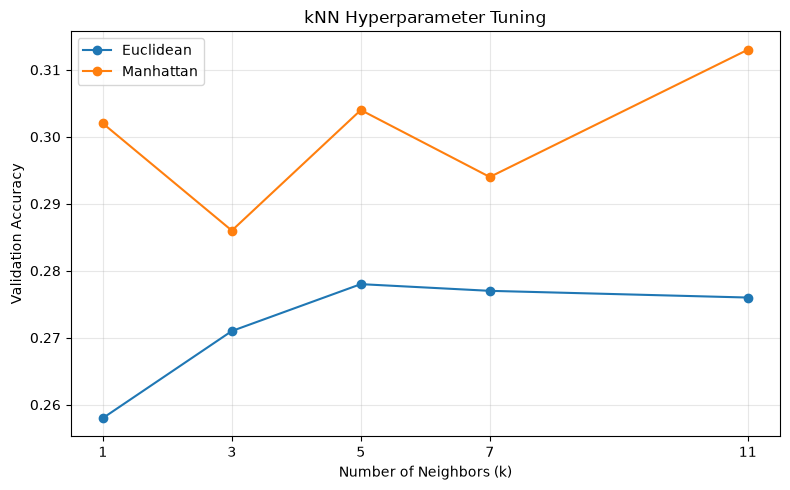

In [10]:
plt.figure(figsize=(8, 5))

for metric in metrics:
    accuracies = [
        r["accuracy"]
        for r in results
        if r["metric"] == metric
    ]

    plt.plot(
        k_values,
        accuracies,
        marker="o",
        label=metric.capitalize()
    )

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Validation Accuracy")
plt.title("kNN Hyperparameter Tuning")
plt.xticks(k_values)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
best_result = max(results, key=lambda r: r["accuracy"])

print("Best k:", best_result["k"])
print("Best distance metric:", best_result["metric"])
print("Best validation accuracy:", best_result["accuracy"])

Best k: 11
Best distance metric: manhattan
Best validation accuracy: 0.313


In [12]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Train the best kNN model
best_knn = KNeighborsClassifier(
    n_neighbors=best_result["k"],
    metric=best_result["metric"],
    algorithm="brute",
    n_jobs=-1
)

best_knn.fit(X_train_flat, y_train)

# Predict test data
y_test_pred = best_knn.predict(X_test_flat)

# Evaluate performance
test_accuracy = accuracy_score(y_test_small, y_test_pred)

print(f"Test Accuracy: {test_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test_small,
    y_test_pred,
    target_names=class_names,
    zero_division=0
))

Test Accuracy: 0.2910

Classification Report:
              precision    recall  f1-score   support

    airplane       0.32      0.57      0.41       100
  automobile       0.50      0.08      0.14       100
        bird       0.20      0.37      0.26       100
         cat       0.19      0.07      0.10       100
        deer       0.21      0.48      0.29       100
         dog       0.33      0.18      0.23       100
        frog       0.24      0.21      0.22       100
       horse       0.52      0.12      0.20       100
        ship       0.41      0.61      0.49       100
       truck       0.58      0.22      0.32       100

    accuracy                           0.29      1000
   macro avg       0.35      0.29      0.27      1000
weighted avg       0.35      0.29      0.27      1000



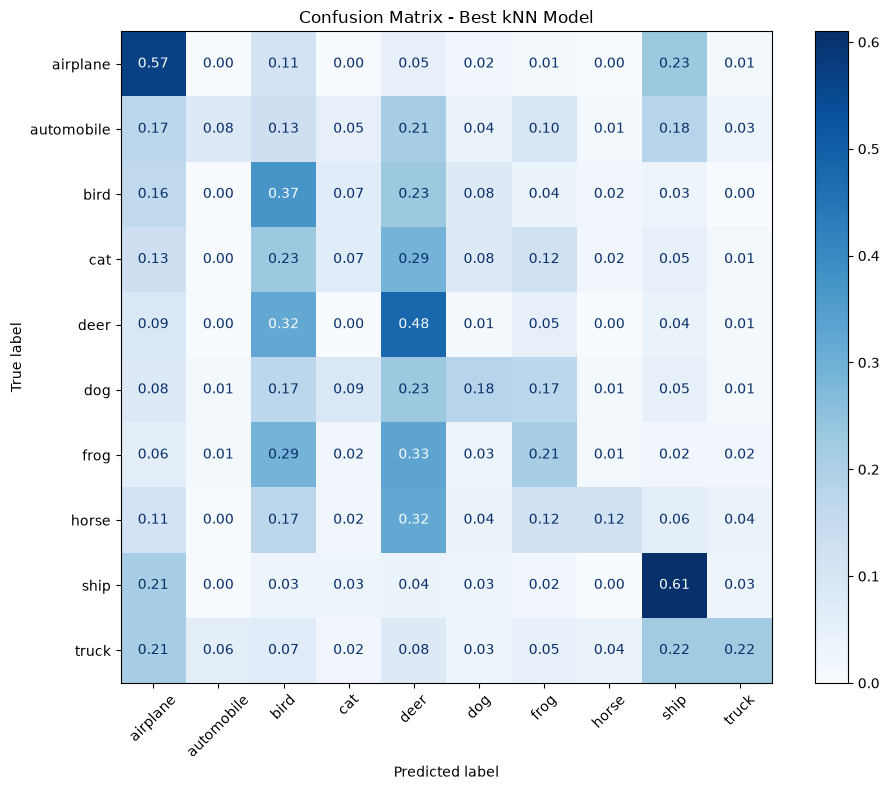

In [13]:
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_test_small,
    y_test_pred,
    display_labels=class_names,
    normalize="true",
    cmap="Blues",
    xticks_rotation=45,
    values_format=".2f",
    ax=ax
)

plt.title("Confusion Matrix - Best kNN Model")
plt.tight_layout()
plt.show()

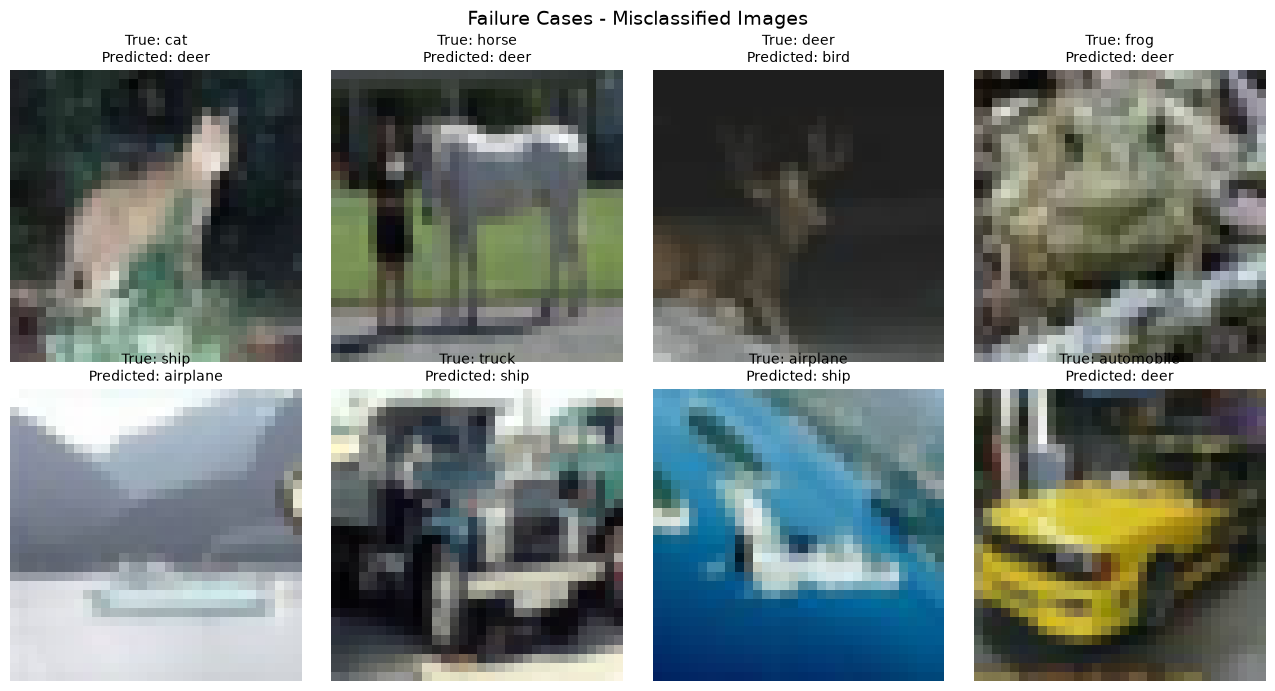

In [14]:
failure_pairs = [
    (3, 4),  # cat -> deer
    (7, 4),  # horse -> deer
    (4, 2),  # deer -> bird
    (6, 4),  # frog -> deer
    (8, 0),  # ship -> airplane
    (9, 8),  # truck -> ship
    (0, 8),  # airplane -> ship
    (1, 4)   # automobile -> deer
]

fig, axes = plt.subplots(2, 4, figsize=(13, 7))

for ax, (true_label, pred_label) in zip(axes.flat, failure_pairs):

    indices = np.where(
        (y_test_small == true_label) &
        (y_test_pred == pred_label)
    )[0]

    if len(indices) > 0:
        idx = indices[0]

        ax.imshow(X_test_small[idx])

        ax.set_title(
            f"True: {class_names[true_label]}\n"
            f"Predicted: {class_names[pred_label]}",
            fontsize=10
        )

    ax.axis("off")

plt.suptitle(
    "Failure Cases - Misclassified Images",
    fontsize=14
)

plt.tight_layout()
plt.show()